In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import pybnesian as pbn
from adapted_MMCIT import MMCIT

In [ ]:
# 1. Petición directa a apidatos.ree.es (Demanda real peninsular de un mes)
url = "https://apidatos.ree.es/es/datos/demanda/demanda-tiempo-real"
params = {
    "start_date": "2026-05-16T00:00",
    "end_date": "2026-05-24T23:59",
    "time_trunc": "hour"  # O 'five_minutes' para tener miles de puntos
}
headers = {"Accept": "application/json"}

response = requests.get(url, params=params, headers=headers)
data = response.json()

# 2. Extraer los valores (el primer elemento suele ser 'Demanda real')
valores = data["included"][0]["attributes"]["values"]
df = pd.DataFrame(valores)

# 3. Convertir fecha a hora continua
df["datetime"] = pd.to_datetime(df["datetime"], utc=True).dt.tz_convert("Europe/Madrid")
df["hora_continua"] = df["datetime"].dt.hour + df["datetime"].dt.minute / 60.0
df["hora_continua"] = (df["hora_continua"] - 4) % 24
df["demanda_gw"] = df["value"].astype(float) / 1000
df["is_weekend"] = df["datetime"].dt.dayofweek >= 5
df["is_weekend"] = df["is_weekend"].astype('str').astype('category')
df = df.sample(1000, random_state=67)

In [4]:
pval = MMCIT(df[["hora_continua", "demanda_gw"]]).pvalue("hora_continua", "demanda_gw", [])
print(f"MMCIT: p = {pval:.4f}")
pval = pbn.MixedKMutualInformation(df=df[["hora_continua", "demanda_gw"]], k=len(df)//10, shuffle_neighbors=5,
        samples=100,
        scaling="normalized_rank",
        gamma_approx=True,
        adaptive_k=True
    ).pvalue("hora_continua", "demanda_gw")
print(f"KNNCIT: p = {pval:.4f}")


MMCIT: p = 0.9046
KNNCIT: p = 0.0099


In [5]:
pval = MMCIT(df[["hora_continua", "demanda_gw", "is_weekend"]]).pvalue("hora_continua", "demanda_gw", ["is_weekend"])
print(f"MMCIT: p = {pval:.4f}")
pval = pbn.MixedKMutualInformation(df=df[["hora_continua", "demanda_gw", "is_weekend"]], k=len(df)//10, shuffle_neighbors=5,
        samples=100,
        scaling="normalized_rank",
        gamma_approx=True,
        adaptive_k=True
    ).pvalue("hora_continua", "demanda_gw", ["is_weekend"])
print(f"KNNCIT: p = {pval:.4f}")

MMCIT: p = 0.8033
KNNCIT: p = 0.0099


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


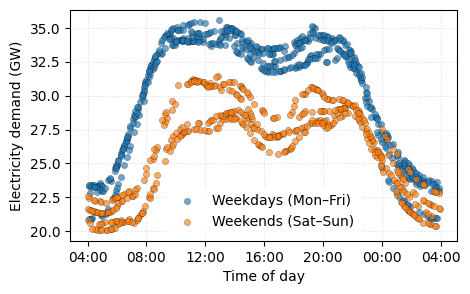

In [7]:
df_we = df[df["is_weekend"] == 'True']
df_wd = df[df["is_weekend"] == 'False']

fig, ax = plt.subplots(figsize=(5, 3))

# Shared color scale across both subsets so the colorbar stays consistent
vmin, vmax = df["demanda_gw"].min(), df["demanda_gw"].max()

# Plot Weekdays (Circles)
sc = ax.scatter(
    df_wd["hora_continua"], df_wd["demanda_gw"],alpha=0.65, s=20, edgecolors="k", linewidths=0.25,
    label="Weekdays (Mon–Fri)", zorder=2
)

# Plot Weekends (Triangles)
ax.scatter(
    df_we["hora_continua"], df_we["demanda_gw"], alpha=0.65, s=20, edgecolors="k", linewidths=0.25,
    label="Weekends (Sat–Sun)", zorder=2
)

# Map X-axis ticks back to real 24h clock format
tick_locs = [0, 4, 8, 12, 16, 20, 24]
tick_labels = ["04:00", "08:00", "12:00", "16:00", "20:00", "00:00", "04:00"]
ax.set_xticks(tick_locs)
ax.set_xticklabels(tick_labels)

ax.set_xlabel("Time of day")
ax.set_ylabel("Electricity demand (GW)")
ax.grid(True, linestyle=":", alpha=0.4, zorder=1)
ax.legend(loc="lower center", frameon=True, facecolor="white", framealpha=0.92, edgecolor="none")
plt.savefig(f'./results/real/REE.eps', format = 'eps', bbox_inches='tight')